# COVARIANCE CHANGE

Here we try to understand what is causing the change in covariance between U and LWA. We find that the change in covariance is mostly negative and it is mostly driven by a change in mean zonal winds.

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 10

# --- INPUT ---
# Assume you have xarray DataArrays: lwa and ucomp, with dims ('time','lat','lon')
# ref: reference period (e.g., control)
# pert: perturbed period (e.g., experiment)

pert = xr.open_dataset('/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_KS_30_72,90/tot/filtered_decomposition_data_flipped_2-51.nc')
ref = xr.open_dataset('/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot/filtered_decomposition_data_flipped_2-51.nc')

lat = pert['lat']
ucomp_ref = ref['ucomp']# - ref['ucomp'].mean('time')
ucomp_pert = pert['ucomp']#  - pert['ucomp'].mean('time')
cosphi = np.cos(np.deg2rad(lat)).broadcast_like(ucomp_ref)
dw_lwa_ref = (ref['dw_lwa'])/cosphi
dw_lwa_pert = (pert['dw_lwa'])/cosphi
var_ref = dw_lwa_ref.var(dim='time')
var_pert = dw_lwa_pert.var(dim='time')

# --- 1. Means ---
E_X_ref = ucomp_ref.mean(dim='time')# * np.sqrt(dw_lwa_var_ref)
E_Y_ref = dw_lwa_ref.mean(dim='time')# * np.sqrt(dw_lwa_var_ref)
E_X_pert = ucomp_pert.mean(dim='time')# * np.sqrt(dw_lwa_var_pert)
E_Y_pert = dw_lwa_pert.mean(dim='time')# * np.sqrt(dw_lwa_var_pert)

# --- 2. Raw joint moments ---
E_XY_ref = (ucomp_ref*dw_lwa_ref).mean(dim='time')# * dw_lwa_var_ref
E_XY_pert = (ucomp_pert*dw_lwa_pert).mean(dim='time')# * dw_lwa_var_pert


#add a minus sign because we are speaking about Covariance
# --- 3. Actual covariance values ---
cov_ref = (E_XY_ref - E_X_ref*E_Y_ref)
cov_pert = (E_XY_pert - E_X_pert*E_Y_pert)
delta_cov = cov_pert - cov_ref


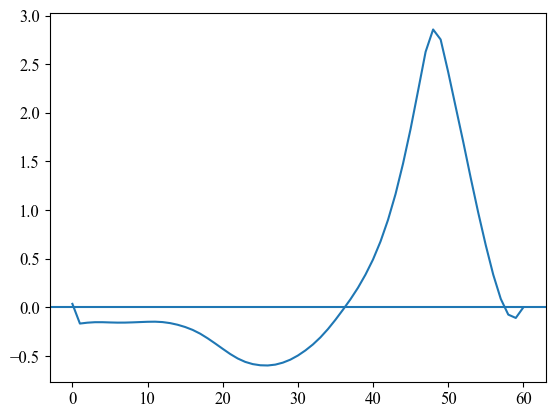

In [2]:
plt.plot(dw_lwa_pert.mean('lon').mean('time')-dw_lwa_ref.mean('lon').mean('time'))
plt.axhline(0)
#plt.plot(dw_lwa_pert.mean('lon').mean('time'))


In [3]:
#IMPORT RWB DATA

DAV_freq_ref = xr.open_dataset("/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot/DAV_tracked_unfilt_flipped_2.5x2.5_daily_2-51.nc")['DAV_freq']
DAV_freq_pert = xr.open_dataset("/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_KS_30_72,90/tot/DAV_tracked_unfilt_flipped_2.5x2.5_daily_2-51.nc")['DAV_freq']

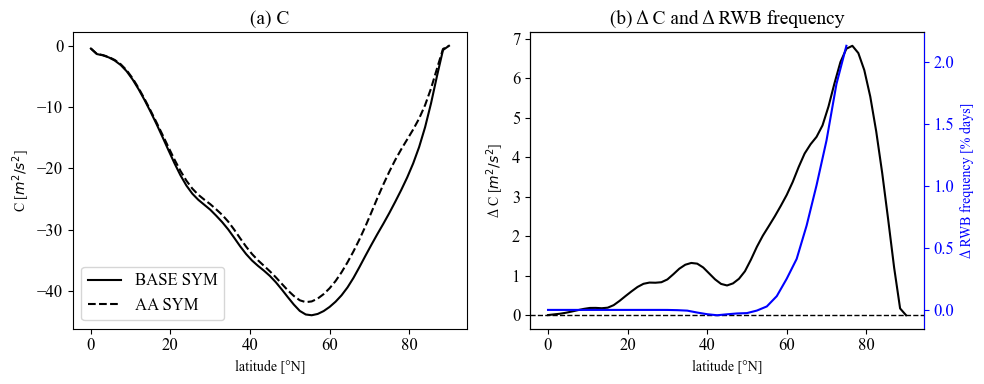

In [12]:
#plot delta covariance zonal average

cov_ref_zonavg = cov_ref.mean(dim='lon')
cov_pert_zonavg = cov_pert.mean(dim='lon')
delta_cov_zonavg = cov_pert_zonavg - cov_ref_zonavg

lat = cov_ref['lat']
lat_block = DAV_freq_ref['lat']

# Create a figure with 2 panels in a row (1 row, 2 columns)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

# Access the panels
axes[0].plot(lat,cov_ref_zonavg,color='k',linestyle='solid',label='BASE SYM')
axes[0].plot(lat,cov_pert_zonavg,color='k',linestyle='dashed',label='AA SYM')
axes[0].set_ylabel(r"C [$m^2/s^2$]", color='k')
axes[0].set_xlabel("latitude [°N]", color='k')
axes[0].legend()
axes[0].set_title("(a) C")

# Example content
axes[1].plot(lat,delta_cov_zonavg,color='k',linestyle='solid')
axes[1].set_ylabel(r"Δ C [$m^2/s^2$]", color='k')
axes[1].set_xlabel("latitude [°N]", color='k')
axes[1].axhline(0, color='k', linestyle='--', linewidth=1)
ax1_right = axes[1].twinx()
data = DAV_freq_pert.mean(dim='lon')-DAV_freq_ref.mean(dim='lon')
ax1_right.plot(lat_block,data.where(data.lat <= 75),color='blue')
ax1_right.set_ylabel("Δ RWB frequency [% days]", color='blue')
ax1_right.tick_params(axis='y', colors='blue')
ax1_right.spines['right'].set_color('blue')
axes[1].set_title("(b) Δ C and Δ RWB frequency")

plt.tight_layout()
plt.savefig('supplementary_plots/Figure_S1.png',dpi=300)


# $\beta$ changes

Here we combine the informations from above with the changes in the variances of LWA, which contribute to estimating $\alpha$, the regression coefficient between LWA and U.  
We find that the midlatitude V increase is even more important in shaping the ALPHA response to arctic amplification.  
On the other hand, the decrease of V at high latitudes compensate the decrease of covariance of U and LWA, resulting in a net zero effect on $\alpha$

In [13]:
# import wind shear data
ubaro_aa_filtered = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/filtered_decomposition_data_flipped_2-51.nc')['ucomp']
ubaro_base_filtered = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/filtered_decomposition_data_flipped_2-51.nc')['ucomp']

R = 6.371e6  # Earth radius in meters

lat_rad = np.deg2rad(ubaro_aa_filtered.lat)
coslat = np.cos(lat_rad)

wind_shear_aa = (ubaro_aa_filtered.mean('time').differentiate("lat") *  np.pi / 180)/R
wind_shear_base = (ubaro_base_filtered.mean('time').differentiate("lat") *  np.pi / 180)/R

lat_wind = wind_shear_aa['lat']

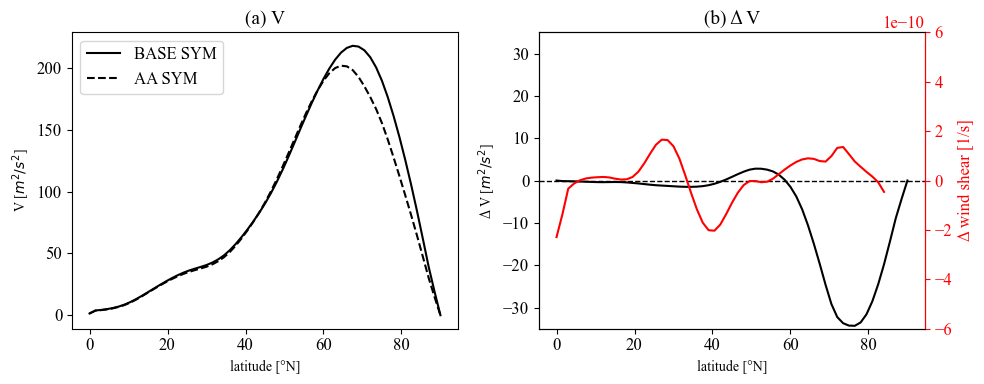

In [19]:
#plot delta covariance zonal average

var_ref_zonavg = var_ref.mean(dim='lon')
var_pert_zonavg = var_pert.mean(dim='lon')
delta_var_zonavg = var_pert_zonavg - var_ref_zonavg

# Create a figure with 2 panels in a row (1 row, 2 columns)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

# Access the panels
axes[0].plot(lat,var_ref_zonavg,color='k',linestyle='solid',label='BASE SYM')
axes[0].plot(lat,var_pert_zonavg,color='k',linestyle='dashed',label='AA SYM')
axes[0].set_ylabel(r"V [$m^2/s^2$]", color='k')
axes[0].set_xlabel("latitude [°N]", color='k')
axes[0].legend()
axes[0].set_title("(a) V")

# Example content
#data = dw_lwa_pert.mean('lon').mean('time')-dw_lwa_ref.mean('lon').mean('time')
data = delta_var_zonavg
axes[1].plot(lat,data,color='k',linestyle='solid')
axes[1].set_ylabel(r"Δ V [$m^2/s^2$]", color='k')
axes[1].set_xlabel("latitude [°N]", color='k')
axes[1].axhline(0, color='k', linestyle='--', linewidth=1)
axes[1].set_ylim(-35,+35)
#axes[1].set_ylim(-3,+3)

#plt.plot(dw_lwa_pert.mean('lon').mean('time')-dw_lwa_ref.mean('lon').mean('time'))
#plt.axhline(0)

ax1_right = axes[1].twinx()
data = wind_shear_aa.mean('lon')-wind_shear_base.mean('lon')
ax1_right.plot(lat,data.where(data.lat <= 85),color='red')
ax1_right.set_ylabel("Δ wind shear [1/s]", color='red',fontsize=12)
ax1_right.tick_params(axis='y', colors='red')
ax1_right.spines['right'].set_color('red')
ax1_right.set_ylim(-6e-10,+6e-10)

axes[1].set_title("(b) Δ V")

plt.tight_layout()
plt.savefig('supplementary_plots/Figure_S2.png',dpi=300)


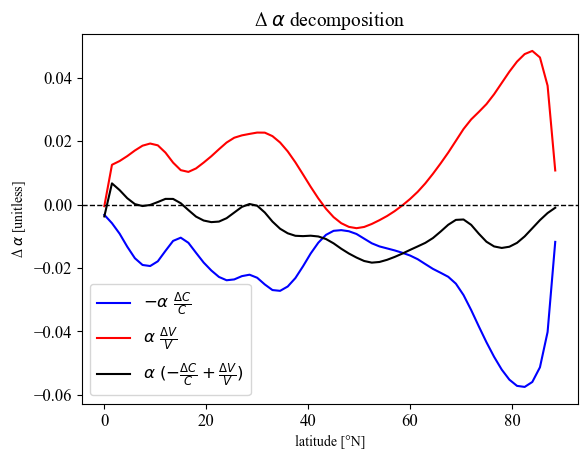

In [16]:

# Assume you already have:
# cov_ref, cov_pert, var_ref, var_pert  (all xarray DataArray, dims lat/lon)
# derived earlier as:
# cov_ref  = E_XY_ref  - E_X_ref * E_Y_ref
# cov_pert = E_XY_pert - E_X_pert * E_Y_pert
# var_ref, var_pert = lwa_ref.var(dim='time'), lwa_pert.var(dim='time')
"""
# Delta cov and delta beta actual
dC = cov_pert - cov_ref
beta_ref  = cov_ref  / var_ref
beta_pert = cov_pert / var_pert
dBeta_actual = beta_pert - beta_ref

# --- Decomposition A (denominator = var_pert) ---
dBeta_cov_A = dC / var_pert                      # ΔC / Vp
dBeta_var_A = cov_ref * (1/var_pert - 1/var_ref) # Cr*(1/Vp - 1/Vr)
dBeta_A_sum = dBeta_cov_A + dBeta_var_A          # should equal dBeta_actual (within numerical tolerance)

# --- Decomposition B (denominator = var_ref) ---
dBeta_cov_B = dC / var_ref                       # ΔC / Vr
dBeta_var_B = cov_pert * (1/var_pert - 1/var_ref) # Cp*(1/Vp - 1/Vr)
dBeta_B_sum = dBeta_cov_B + dBeta_var_B

# --- Zonal means ---
dBeta_actual_zm = dBeta_actual.mean(dim="lon")
dBeta_cov_A_zm  = dBeta_cov_A.mean(dim="lon")
dBeta_var_A_zm  = dBeta_var_A.mean(dim="lon")
dBeta_A_sum_zm  = dBeta_A_sum.mean(dim="lon")
"""

cov_term = cov_pert_zonavg/var_pert_zonavg*((cov_pert_zonavg-cov_ref_zonavg)/cov_pert_zonavg)

var_term = cov_ref_zonavg/var_ref_zonavg*((var_pert_zonavg-var_ref_zonavg)/var_pert_zonavg)

tot_term = -(cov_term-var_term)

#add a minus sign
plt.plot(lat,-cov_term,color='blue',label=r'$-\alpha\ \frac{\Delta C}{C}$')
plt.plot(lat,var_term,color='red',label=r'$\alpha\ \frac{\Delta V}{V}$')
plt.plot(lat,tot_term,color='black',label=r'$\alpha\ (-\frac{\Delta C}{C}+\frac{\Delta V}{V})$')
plt.ylabel(r"Δ $\alpha$ [unitless]", color='k')
plt.xlabel("latitude [°N]", color='k')
plt.axhline(0, color='k', linestyle='--', linewidth=1)
plt.title(r"Δ $\alpha$ decomposition")
plt.legend()

plt.savefig('supplementary_plots/Figure_S3.png',dpi=300)

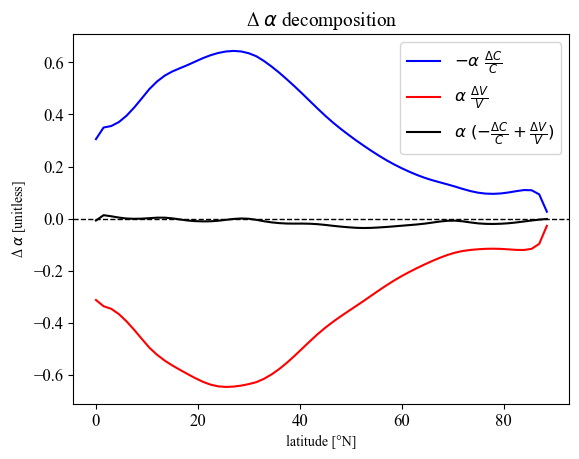

In [17]:
# Assume you already have:
# cov_ref, cov_pert, var_ref, var_pert  (all xarray DataArray, dims lat/lon)
# derived earlier as:
# cov_ref  = E_XY_ref  - E_X_ref * E_Y_ref
# cov_pert = E_XY_pert - E_X_pert * E_Y_pert
# var_ref, var_pert = lwa_ref.var(dim='time'), lwa_pert.var(dim='time')
"""
# Delta cov and delta beta actual
dC = cov_pert - cov_ref
beta_ref  = cov_ref  / var_ref
beta_pert = cov_pert / var_pert
dBeta_actual = beta_pert - beta_ref

# --- Decomposition A (denominator = var_pert) ---
dBeta_cov_A = dC / var_pert                      # ΔC / Vp
dBeta_var_A = cov_ref * (1/var_pert - 1/var_ref) # Cr*(1/Vp - 1/Vr)
dBeta_A_sum = dBeta_cov_A + dBeta_var_A          # should equal dBeta_actual (within numerical tolerance)

# --- Decomposition B (denominator = var_ref) ---
dBeta_cov_B = dC / var_ref                       # ΔC / Vr
dBeta_var_B = cov_pert * (1/var_pert - 1/var_ref) # Cp*(1/Vp - 1/Vr)
dBeta_B_sum = dBeta_cov_B + dBeta_var_B

# --- Zonal means ---
dBeta_actual_zm = dBeta_actual.mean(dim="lon")
dBeta_cov_A_zm  = dBeta_cov_A.mean(dim="lon")
dBeta_var_A_zm  = dBeta_var_A.mean(dim="lon")
dBeta_A_sum_zm  = dBeta_A_sum.mean(dim="lon")
"""

cov_term = cov_pert_zonavg/var_pert_zonavg*(cov_pert_zonavg/cov_ref_zonavg)

var_term = cov_ref_zonavg/var_ref_zonavg*(var_pert_zonavg/var_ref_zonavg)

tot_term = -(cov_term-var_term)

#add a minus sign
plt.plot(lat,-cov_term,color='blue',label=r'$-\alpha\ \frac{\Delta C}{C}$')
plt.plot(lat,var_term,color='red',label=r'$\alpha\ \frac{\Delta V}{V}$')
plt.plot(lat,tot_term,color='black',label=r'$\alpha\ (-\frac{\Delta C}{C}+\frac{\Delta V}{V})$')
plt.ylabel(r"Δ $\alpha$ [unitless]", color='k')
plt.xlabel("latitude [°N]", color='k')
plt.axhline(0, color='k', linestyle='--', linewidth=1)
plt.title(r"Δ $\alpha$ decomposition")
plt.legend()

plt.savefig('supplementary_plots/Figure_S3.png',dpi=300)